In [1]:
import time
start_time=time.time()

In [2]:
import json
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
from astropy.io import fits
from astropy.table import Table
import json
import sys

In [3]:
sys.path.append(str(Path().resolve() / 'py_modules')) 

from rebin_utils import downsample

from astronomical_objects import OBJECTS, print_available_objects
from spectral_lines import LINES, print_available_lines
from astronomical_instruments import INSTRUMENTS, print_available_instruments

# Import from pipeline_config and py_modules
from pipeline_config import OBSERVATIONS_DIR, MAPS_DIR, FIGS_DIR

In [4]:
cfg = LINES["Halpha"]
nebula = OBJECTS["30Doradus"]
instrument = INSTRUMENTS["MUSE"]


In [5]:
bins = 3


In [6]:
plot_label      = cfg.plot_label
rest_wavelength = cfg.rest_wavelength
element         = cfg.element
ion             = cfg.ion
transition_id   = cfg.transition_id

In [7]:
dist      = nebula.distance_pc
object_id = nebula.object_id

In [8]:
pix     = instrument.arcsec_per_pixel
inst_id = instrument.instrument_id

In [9]:
name_id      =  inst_id + '-' + object_id + '-' + element + '-' + 'bin' + str(bins)
name_label   =  inst_id + ' ' + plot_label

In [10]:
pc         = dist*(2*np.pi) / (360 * 60 * 60) # value in parsecs of each arcsec
s0_        = 0.9    # proposed seeing
s0         = (s0_*pc) / 2.355    # RMS seeing [parsecs]

In [11]:
print('distance:', dist, 'pc')
print('spatial_scale:', pix, 'arcsec/pix')
print(pc, 'pc/arcsec')
print(name_id)
print(name_label)

distance: 50000 pc
spatial_scale: 0.2 arcsec/pix
0.24240684055476797 pc/arcsec
MUSE-30Dor-H-bin3
MUSE H$\alpha$


Loading files

In [12]:
name_file ='MUSE-Dor-H'
data_file = name_file + '.fits'

In [13]:
fits_file = OBSERVATIONS_DIR / data_file

In [14]:
with fits.open(fits_file) as hdul:
    n = None
    sb_raw = hdul[1].data[:n, :n].astype(np.float64)
    vv_raw = hdul[2].data[:n, :n].astype(np.float64)
    ss_raw = hdul[3].data[:n, :n].astype(np.float64)
    hdul.info()

Filename: C:\Users\javas\Dropbox\GitHub\VIENTO\structure_function_analysis\MUSE_30dor\observations\MUSE-Dor-H.fits
No.    Name      Ver    Type      Cards   Dimensions   Format
  0  PRIMARY       1 PrimaryHDU    1158   ()      
  1  DATA          1 ImageHDU        52   (650, 650)   float64   
  2  DATA          1 ImageHDU        52   (650, 650)   float64   
  3  DATA          1 ImageHDU        52   (650, 650)   float64   


In [15]:
#m = ~np.isfinite(sb_raw*vv_raw*ss_raw) | (sb_raw < 0.0)

sb = sb_raw
vv = vv_raw
ss = ss_raw

#sb[m] = 0.0
#vv[m] = np.nanmean(vv)
sb /= sb.max()

#good = (~m) & (sb > 0.001)

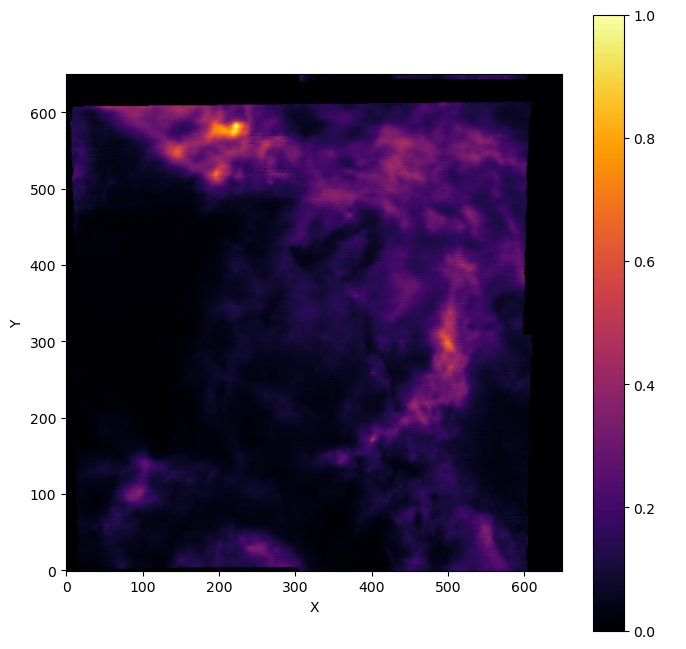

In [16]:
fig, ax = plt.subplots(figsize=(8, 8))

plt.figure(1)
plt.imshow(sb, cmap='inferno')

cbar = plt.colorbar()
#plt.clim(0.001,1)
cbar.set_label(' ', rotation=270, labelpad=15)  

ax.set_xlabel('X')
ax.set_ylabel('Y')

plt.gca().invert_yaxis()

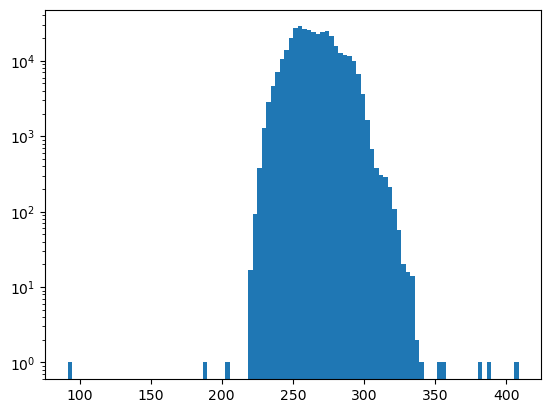

In [17]:
fig, ax = plt.subplots()
plt.hist(vv[np.isfinite(vv)& (np.abs(vv) < 600)] , bins=100)
ax.set_yscale("log")

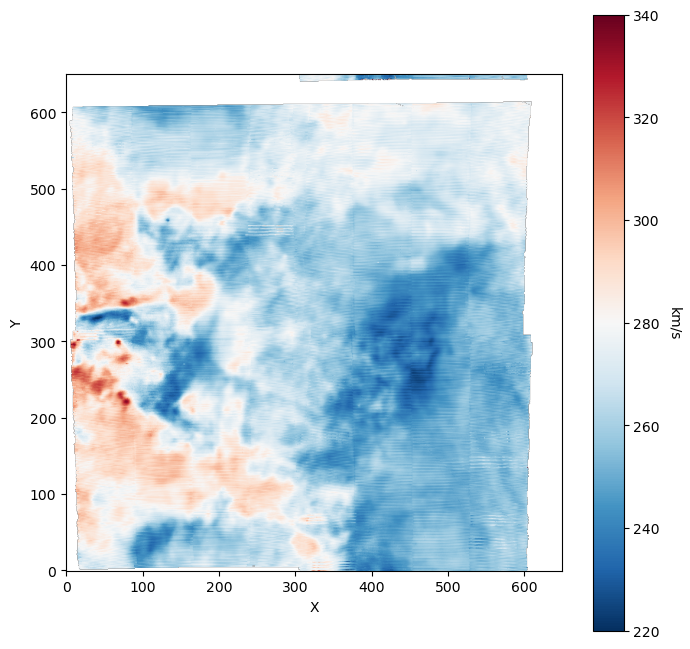

In [18]:
fig, ax = plt.subplots(figsize=(8, 8))

plt.figure(1)
plt.imshow(vv, cmap='RdBu_r')

cbar = plt.colorbar()
plt.clim(220,340)
cbar.set_label('km/s', rotation=270, labelpad=15)  

ax.set_xlabel('X')
ax.set_ylabel('Y')

plt.gca().invert_yaxis()

# Downsampling

In [19]:
prod_map  = sb_raw * vv_raw
sb_       = pd.notna(sb_raw)
vv_       = pd.notna(vv_raw)
#m_     = pd.notna(m)
prod_map_ = sb_ * vv_

In [20]:
mingoods  = [1]*bins

for mingood in zip(mingoods):
 [sb], sb_= downsample([sb], sb_, mingood=mingood)

for mingood in zip(mingoods):
 [prod_map], prod_map_= downsample([prod_map], prod_map_, mingood=mingood)

#for mingood in zip(mingoods):
# [m], m_= downsample([m], m_, mingood=mingood)

# Binned vv map and boolean mask
vv = prod_map/sb
#mask = mask.astype(bool)

C:\Users\javas\Dropbox\GitHub\VIENTO\structure_function_analysis\MUSE_30dor\new_analysis\py_modules\rebin_utils.py:107: RuntimeWarning: invalid value encountered in divide
  (
C:\Users\javas\AppData\Local\Temp\ipykernel_5112\2077147922.py:13: RuntimeWarning: invalid value encountered in divide
  vv = prod_map/sb


# Masking

In [21]:
m = ~np.isfinite(sb*vv) | (sb < 0.0)

sb[m] = 0.0
vv[m] = np.nanmean(vv)
sb /= sb.max()

#good = (~m) & (sb > 0.001)

In [22]:
vv = np.where(~m, vv, np.nan)     
sb = np.where(~m, sb, np.nan) 

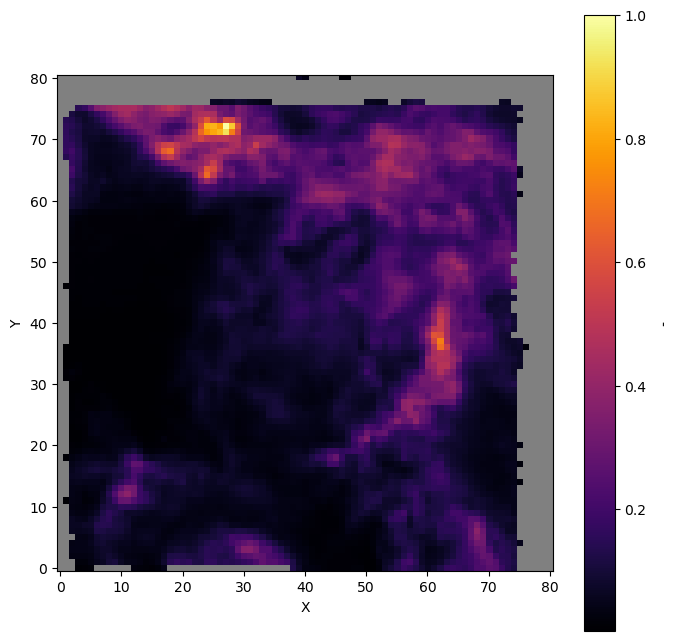

In [23]:
fig, ax = plt.subplots(figsize=(8, 8))

# Get colormap and define color for NaN/masked values
cmap = plt.cm.inferno.copy()
cmap.set_bad(color='gray')

# Plot
im = ax.imshow(
    sb,
    cmap=cmap,
#    vmin=220,
#    vmax=340
)

# Colorbar
cbar = fig.colorbar(im, ax=ax)
cbar.set_label('-', rotation=270, labelpad=15)

# Labels
ax.set_xlabel('X')
ax.set_ylabel('Y')

ax.invert_yaxis()

plt.show()

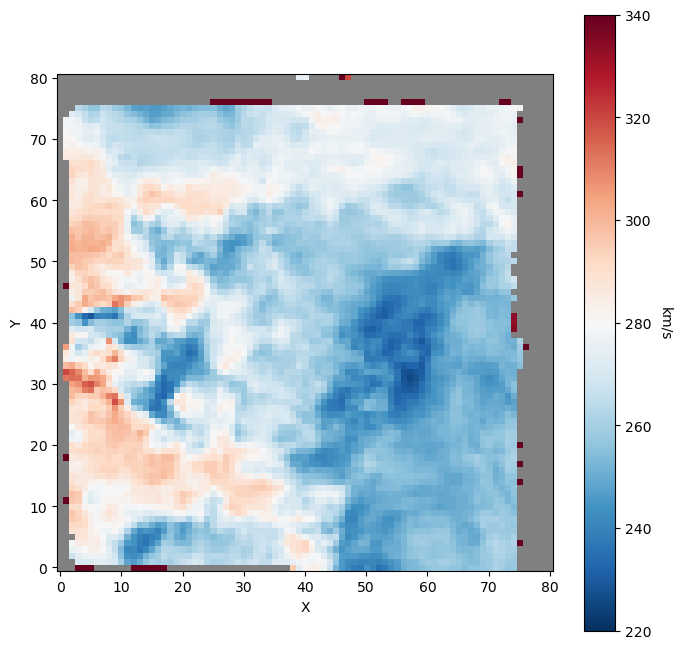

In [24]:
fig, ax = plt.subplots(figsize=(8, 8))

# Get colormap and define color for NaN/masked values
cmap = plt.cm.RdBu_r.copy()
cmap.set_bad(color='gray')

# Plot
im = ax.imshow(
    vv,
    cmap=cmap,
    vmin=220,
    vmax=340
)

# Colorbar
cbar = fig.colorbar(im, ax=ax)
cbar.set_label('km/s', rotation=270, labelpad=15)

# Labels
ax.set_xlabel('X')
ax.set_ylabel('Y')

ax.invert_yaxis()

plt.show()

Analysis data

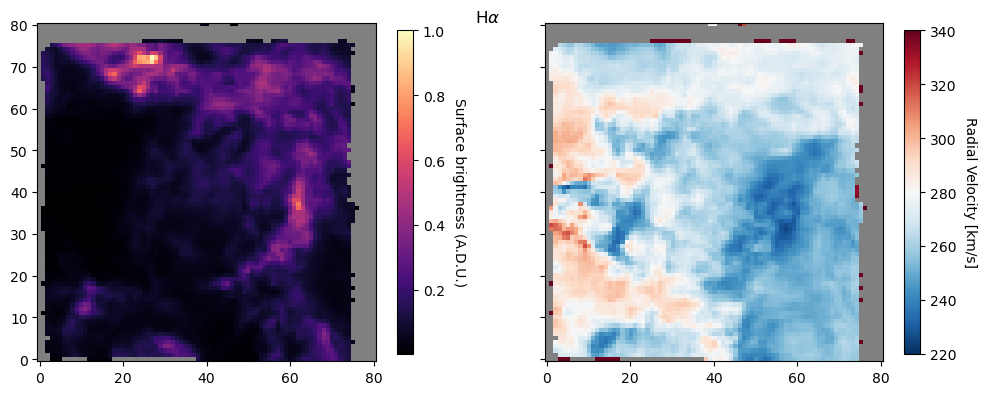

In [25]:
fig, (axx, ax) = plt.subplots(
    1,
    2,
    sharey=True,
    figsize=(12, 6),
)
imshow_kwds = dict(origin="lower", cmap="RdBu_r")
imshow_kwds2 = dict(origin="lower", cmap="magma")
im = ax.imshow(vv, vmin=220, vmax=340, **imshow_kwds)
im.cmap.set_bad(color='gray')
cbar = fig.colorbar(im, ax=[ax], shrink=0.7)
cbar.set_label("Radial Velocity [km/s]", rotation=270, labelpad=15)
im = axx.imshow(sb, **imshow_kwds2)
im.cmap.set_bad(color='gray')
cbar = fig.colorbar(im, ax=[axx], shrink=0.7)
cbar.set_label("Surface brightness (A.D.U.)", rotation=270, labelpad=15)
fig.suptitle(plot_label, y=0.8)

plt.savefig('Imgs/' + name_id + '_ivsv.jpg', bbox_inches='tight') 

In [26]:
N = np.sqrt(vv.shape[0] * vv.shape[1]) * pix * pc
N

3.926990816987241

In [27]:
sig = np.nanstd(vv)
sig

47.14353362620517

# Export

In [28]:
instrument

AstronomicalInstrument(key='MUSE', full_name='Multi Unit Spectroscopic Explorer', instrument_id='MUSE', arcsec_per_pixel=0.2, site='Paranal', telescope='Very Large Telescope, UT4', focus='Nasmyth', instrument_type='Integral field spectrograph, imager', wavelength_coverage='465–930 nm', spectral_resolution='From 1700 in the blue to 3400 in the red', modes=(), notes=None)

In [29]:
primary = fits.PrimaryHDU()
primary.header["FILE"]       = (name_file, "Fits file name")
primary.header["NAME_ID"]    = (name_id, "pipeline identifier")
primary.header["REG"]        = (nebula.catalog_name, "Region catalog name")
primary.header["NAME_REG"]   = (nebula.common_name, "Region name")
primary.header["REG_ID"]     = (object_id, "Region identifier")
primary.header["TYPE_OBJ"]   = (nebula.object_type, "Type object")
primary.header["DIST"]       = (dist, "Distance in parsecs")
primary.header["INSTR"]      = (instrument.instrument_id, "Instrument")
primary.header["LINE"]       = (plot_label, "Emission line name")
primary.header["LINE_ID"]    = (transition_id, "Emission line identifier")
primary.header["L_REST"]     = (rest_wavelength, "Emission line name")
primary.header["SIG"]        = (sig, "Standard deviation vel map")
primary.header["SIG2"]       = (sig**2, "Vel Variance map")
primary.header["S0"]         = (s0, "Atmospheric seeing")
primary.header["BOX_SIZE"]   = (N* (2**bins), "Observational box_size")
primary.header["PC"]         = (pc, "parsec convertion")
primary.header["PIX"]        = (pix* (2**bins), "Instrument pixel scale")
primary.header["BINSIZE"]    = (bins, "Spatial binning factor")
#hdr["noise"]     = (noise, "Instrumental noise")
#hdr["m3D"]       = (m3D, "k = 3 + m3D")
#hdr["ra"]        = (ra, "Artificial correlation length")
#primary.header["SEED1"]     = (randomseed_vv, "Random seed velocity")
#primary.header["SEED2"]     = (randomseed_sb, "Random seed surfavebrightness")
primary.header["AUTHOR"]     = ("J. Garcia-Vazquez", "File creator")

In [30]:
hdu_m0 = fits.ImageHDU(data=sb,  name='MOM0')
hdu_m1 = fits.ImageHDU(data=vv,  name='MOM1')
#hdu_m2 = fits.ImageHDU(data=ss_m[trim],  name='MOM2')
hdu_mk = fits.ImageHDU(data=(m).astype(np.uint8) ,  name='MASK')

In [31]:
hdul = fits.HDUList([primary, hdu_m0, hdu_m1, hdu_mk])
hdul.writeto('fits_ready/' + name_id + '-ivsv.fits', overwrite=True)

In [32]:
with fits.open("fits_ready/" + name_id + "-ivsv.fits") as hdul:
    hdul.info()
    
hdr = hdul[0].header
print(hdr)

Filename: fits_ready/MUSE-30Dor-H-bin3-ivsv.fits
No.    Name      Ver    Type      Cards   Dimensions   Format
  0  PRIMARY       1 PrimaryHDU      23   ()      
  1  MOM0          1 ImageHDU         8   (81, 81)   float64   
  2  MOM1          1 ImageHDU         8   (81, 81)   float64   
  3  MASK          1 ImageHDU         8   (81, 81)   uint8   


SIMPLE  =                    T / conforms to FITS standard                      BITPIX  =                    8 / array data type                                NAXIS   =                    0 / number of array dimensions                     EXTEND  =                    T                                                  FILE    = 'MUSE-Dor-H'         / Fits file name                                 NAME_ID = 'MUSE-30Dor-H-bin3'  / pipeline identifier                            REG     = 'NGC 2070'           / Region catalog name                            NAME_REG= '30 Doradus'         / Region name                                    REG_ID  = '30Dor   '           / Region identifier                              TYPE_OBJ= 'H II region'        / Type object                                    DIST    =                50000 / Distance in parsecs                            INSTR   = 'MUSE    '           / Instrument                                     LINE    = 'H$\alpha$'          / Emissio

In [33]:
print("--- %s seconds ---" % (time.time()-start_time))

--- 3.980346202850342 seconds ---
